# T17 -- Phase 2 candidate peak / candidate-core extraction, manual check

**Scope.** This notebook is a visualization/inspection artifact only. It does not
reimplement any scientific logic -- every particle-slice, KD-tree, support-feature and
candidate-extraction computation below calls directly into `iste.particle_query`,
`iste.kdtree_neighborhood`, `iste.support_features` and `iste.candidate_extraction`
(T14-T17). No `c_hat*`, likelihood, posterior, forward propagation, or source
attribution is computed anywhere here.

**What this demonstrates.** A controlled multimodal synthetic historical particle
slice with three well-separated spatial clusters (A, B, C) is run through the full
T14 -> T15 -> T16 -> T17 chain:

1. `iste.particle_query.HistoricalParticleSlice` is built directly (synthetic input,
   standing in for a T14 query result -- Stage III is not rerun here).
2. `iste.kdtree_neighborhood.build_particle_neighborhood_index` builds the T15 KD-tree
   acceleration structure over the slice's valid particles.
3. `iste.support_features.compute_support_map` evaluates the T16 `Support = f(D, W, V)`
   heat map over a regular query grid.
4. `iste.candidate_extraction.find_candidate_peaks` extracts T17 candidate peaks and
   candidate cores from that support map.

The figure below overlays the detected peaks and candidate-core boundaries on the
support heatmap, with the historical timestamp `t_s` labeled, so the peak/core
extraction behaviour can be checked by eye against the known synthetic cluster
locations -- three clusters in, three distinct candidates out, each centred on its
own cluster.

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np

from iste.particle_query import HistoricalParticleSlice
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.support_features import compute_support_map, SupportFeatureConfig
from iste.candidate_extraction import find_candidate_peaks, CandidateExtractionConfig

## 1. Controlled multimodal synthetic historical particle slice

Three Gaussian-scattered clusters at one historical timestamp `t_s`, all particles
valid (no deaths), with deliberately different sizes, weight scales and
`observation_pixel_id` diversity so the resulting candidates are visibly
distinguishable by `D`/`W`/`V`, not just by location:

| cluster | centre (lat, lon) | n particles | distinct pixels | weight scale |
|---|---|---|---|---|
| A | (20.0, 100.0) | 40 | 3 | 1.5 |
| B | (23.0, 104.0) | 35 | 1 | 0.5 |
| C | (26.5, 101.5) | 15 | 2 | 1.0 |

This is synthetic input standing in for a T14 `query_particle_slice` result -- Stage
III is not rerun, and `HistoricalParticleSlice` is constructed directly with the exact
fields T14 produces.

In [2]:
NAT = np.datetime64("NaT", "ns")
T_S = np.datetime64("2020-01-01T06:00:00", "ns")
rng = np.random.default_rng(7)


def make_cluster(lat0, lon0, n, spread, pixels, weight_mean):
    lat = lat0 + rng.normal(0.0, spread, n)
    lon = lon0 + rng.normal(0.0, spread, n)
    pix = rng.choice(pixels, size=n)
    log_weight = np.log(rng.uniform(weight_mean * 0.7, weight_mean * 1.3, n))
    return lat, lon, pix, log_weight


latA, lonA, pixA, lwA = make_cluster(20.0, 100.0, 40, 0.015, ["px-0", "px-1", "px-2"], 1.5)
latB, lonB, pixB, lwB = make_cluster(23.0, 104.0, 35, 0.015, ["px-3"], 0.5)
latC, lonC, pixC, lwC = make_cluster(26.5, 101.5, 15, 0.018, ["px-4", "px-5"], 1.0)

lat = np.concatenate([latA, latB, latC])
lon = np.concatenate([lonA, lonB, lonC])
pix = np.concatenate([pixA, pixB, pixC]).astype(object)
log_weight = np.concatenate([lwA, lwB, lwC])
n_particles = len(lat)

particle_id = np.array([f"p{i:04d}" for i in range(n_particles)], dtype=object)
forcing_member_id = np.zeros(n_particles, dtype=np.int64)
valid = np.ones(n_particles, dtype=bool)

slice_ = HistoricalParticleSlice(
    particle_id=particle_id,
    observation_pixel_id=pix,
    forcing_member_id=forcing_member_id,
    lat=lat,
    lon=lon,
    log_weight=log_weight,
    valid=valid,
    death_time=np.full(n_particles, NAT, dtype="datetime64[ns]"),
    death_lat=np.full(n_particles, np.nan),
    death_lon=np.full(n_particles, np.nan),
    death_reason=np.array([""] * n_particles, dtype=object),
    query_time=T_S,
)
print(f"slice: {slice_.n_particles} particles at t_s={T_S}")

slice: 90 particles at t_s=2020-01-01T06:00:00.000000000


## 2. T15 KD-tree neighborhood index

Built directly by `iste.kdtree_neighborhood.build_particle_neighborhood_index` --
distance-safe local-metres projection, valid particles only, no logic duplicated here.

In [3]:
index = build_particle_neighborhood_index(slice_)
print(f"neighborhood index built over {len(index.source_row)} valid particles")

neighborhood index built over 90 valid particles


## 3. T16 support map

`iste.support_features.compute_support_map` evaluated over a regular
`lat_grid x lon_grid`, using the default `SupportFeatureConfig` (unit scales/weights,
`linear_support_function`: `Support = D + W + V`). The query grid spans the full
domain (all three clusters plus empty background); `radius_m` is chosen comfortably
larger than the grid's worst-case half-diagonal spacing so every cluster is actually
seen by at least one query point, and large enough that each cluster's nonzero-support
region is visible as a heatmap blob rather than a single pixel.

In [4]:
lat_grid = np.linspace(19.0, 28.0, 91)   # ~0.1 deg spacing (~11 km)
lon_grid = np.linspace(99.0, 106.0, 71)  # ~0.1 deg spacing (~10-11 km at this latitude)
RADIUS_M = 25_000.0
support_config = SupportFeatureConfig()  # defaults: unit scales/weights

lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)  # row-major: shape (n_lat, n_lon)
support_map = compute_support_map(
    index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=RADIUS_M, config=support_config
)
support_grid = np.array([sf.support for sf in support_map]).reshape(len(lat_grid), len(lon_grid))
print(f"support grid: shape={support_grid.shape}, range=[{support_grid.min():.2f}, {support_grid.max():.2f}]")

support grid: shape=(91, 71), range=[0.00, 104.66]


## 4. T17 candidate peak / candidate-core extraction

`iste.candidate_extraction.find_candidate_peaks` run on the support map above --
local-maximum detection via `scipy.ndimage.maximum_filter`, greedy non-maximum
suppression, fixed-radius candidate cores. Expect exactly one candidate per cluster
(three), each centred on its own cluster.

In [5]:
extraction_config = CandidateExtractionConfig(
    peak_neighborhood_cells=5,
    min_separation_m=150_000.0,
    core_radius_m=15_000.0,
)
candidates = find_candidate_peaks(support_map, lat_grid, lon_grid, T_S, extraction_config)
print(f"{len(candidates)} candidates found")
for c in candidates:
    print(
        f"    {c.candidate_id}: peak=(lat={c.y_peak:.3f}, lon={c.x_peak:.3f}) "
        f"support={c.support_score:.2f} D={c.density_score:.0f} "
        f"W={c.weighted_support_score:.2f} V={c.pixel_diversity_score:.0f} "
        f"core_radius_m={c.core_region.radius_m:.0f}"
    )

assert len(candidates) == 3, f"expected 3 distinct candidates, got {len(candidates)}"

3 candidates found
    2020-01-01T06:00:00_cand000: peak=(lat=19.800, lon=100.000) support=104.66 D=40 W=61.66 V=3 core_radius_m=15000
    2020-01-01T06:00:00_cand001: peak=(lat=22.900, lon=103.900) support=53.83 D=35 W=17.83 V=1 core_radius_m=15000
    2020-01-01T06:00:00_cand002: peak=(lat=26.300, lon=101.500) support=33.16 D=15 W=16.16 V=2 core_radius_m=15000


## 5. Visualization: support heatmap + candidate peaks + candidate cores

Left: full-domain support heatmap with every candidate peak (red star) and its core
boundary (red circle) overlaid. Right: one tightly-zoomed panel per candidate, since a
`core_radius_m` of a few km is not visible against the ~700 km full domain. The
historical timestamp `t_s` is labeled in the figure's overall title.

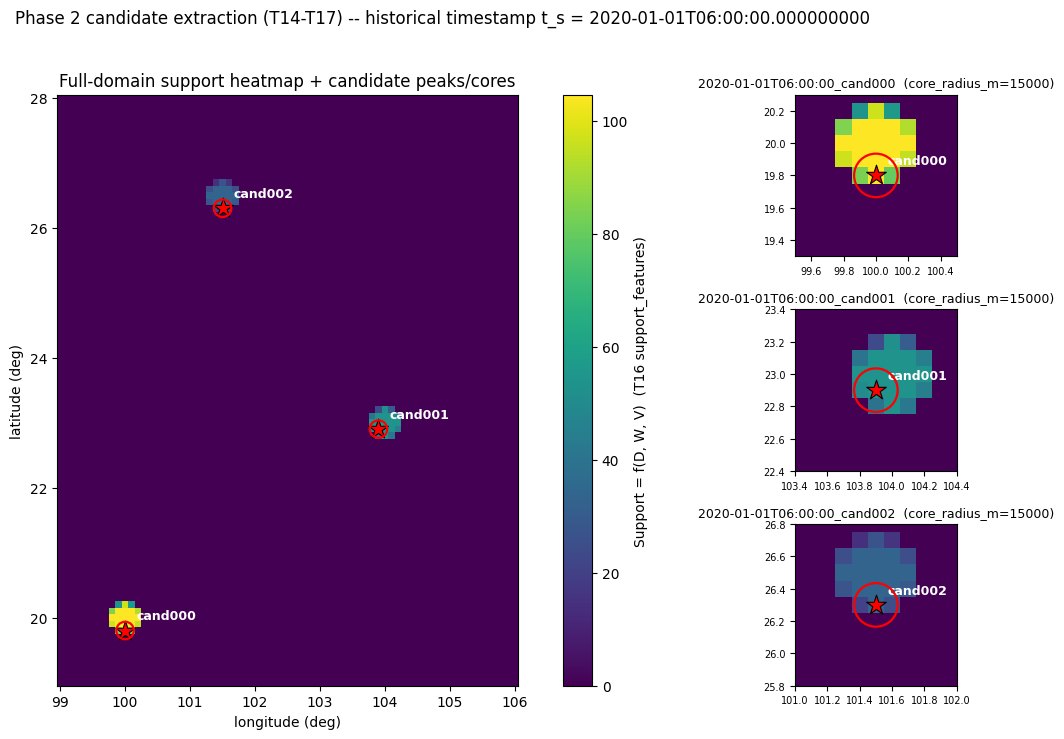

In [6]:
deg_per_m_lat = 1.0 / 111_320.0  # local approx, for drawing core circles only


def draw_candidates(ax, xlim=None, ylim=None):
    for c in candidates:
        ax.scatter(
            [c.x_peak], [c.y_peak], marker="*", s=220, c="red",
            edgecolors="black", linewidths=0.8, zorder=5,
        )
        radius_deg_lat = c.core_region.radius_m * deg_per_m_lat
        ax.add_patch(
            Circle(
                (c.core_region.center_lon, c.core_region.center_lat),
                radius=radius_deg_lat,
                fill=False,
                edgecolor="red",
                linewidth=1.6,
                zorder=5,
            )
        )
        if xlim is None or (xlim[0] <= c.x_peak <= xlim[1] and ylim[0] <= c.y_peak <= ylim[1]):
            ax.annotate(
                c.candidate_id.split("_")[-1],
                (c.x_peak, c.y_peak),
                textcoords="offset points",
                xytext=(8, 8),
                color="white",
                fontsize=9,
                fontweight="bold",
            )


fig = plt.figure(figsize=(13, 7.5))
gs = fig.add_gridspec(3, 2, width_ratios=[2.2, 1.0])

ax_main = fig.add_subplot(gs[:, 0])
mesh = ax_main.pcolormesh(lon_grid, lat_grid, support_grid, shading="auto", cmap="viridis")
fig.colorbar(mesh, ax=ax_main, label="Support = f(D, W, V)  (T16 support_features)")
draw_candidates(ax_main)
ax_main.set_xlabel("longitude (deg)")
ax_main.set_ylabel("latitude (deg)")
ax_main.set_title("Full-domain support heatmap + candidate peaks/cores")
ax_main.set_aspect("equal")

zoom_half_width_deg = 0.5
for i, c in enumerate(sorted(candidates, key=lambda c: c.candidate_id)):
    ax_zoom = fig.add_subplot(gs[i, 1])
    ax_zoom.pcolormesh(lon_grid, lat_grid, support_grid, shading="auto", cmap="viridis")
    xlim = (c.x_peak - zoom_half_width_deg, c.x_peak + zoom_half_width_deg)
    ylim = (c.y_peak - zoom_half_width_deg, c.y_peak + zoom_half_width_deg)
    draw_candidates(ax_zoom, xlim=xlim, ylim=ylim)
    ax_zoom.set_xlim(*xlim)
    ax_zoom.set_ylim(*ylim)
    ax_zoom.set_aspect("equal")
    ax_zoom.set_title(
        f"{c.candidate_id}  (core_radius_m={c.core_region.radius_m:.0f})", fontsize=9
    )
    ax_zoom.tick_params(labelsize=7)

fig.suptitle(
    f"Phase 2 candidate extraction (T14-T17) -- historical timestamp t_s = {T_S}",
    fontsize=12,
)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.96))
plt.show()

## Interpretation limits

- This is a **screening** artifact, not a source estimate. `Support = f(D, W, V)` is a
  configurable Phase 2 heuristic combining local particle density, summed Stage III
  transport/Jacobian weights, and observation-pixel diversity -- it is not a
  probability, likelihood, or posterior density.
- Candidate cores are, in this prototype, fixed-radius circles
  (`CandidateExtractionConfig.core_radius_m`) -- a configuration choice, not a claim of
  physical or statistical optimality (`README.md` leaves the exact core definition
  open).
- "The entire KDE is not automatically treated as the source": only discrete,
  non-suppressed local maxima become candidates -- multiple spatial modes are
  preserved rather than collapsed to one centroid, as shown by the three separate
  clusters above producing three separate candidates.
- No forward propagation, particle sampling, AIS, likelihood evaluation, posterior
  inference, or source attribution is performed by T17 or by this notebook -- those
  are later Phase 2 tasks (T18 onward).